# Phase D — Python / Pandas Analysis

## Restaurant Performance Analytics Project

This phase focuses on data preparation, exploratory data analysis,
statistical analysis, relationship analysis, and visualization
using Python, Pandas, NumPy, Matplotlib, and Seaborn.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", None)

## 2. Load the Five Raw Datasets

In [3]:
cuisines = pd.read_csv("../Raw Data/cuisines.csv")
customers = pd.read_csv("../Raw Data/customers.csv")
locations = pd.read_csv("../Raw Data/locations.csv")
orders = pd.read_csv("../Raw Data/orders.csv")
restaurants = pd.read_csv("../Raw Data/restaurants.csv")

### Dataset Dimensions

In [4]:
print("Cuisines   :", cuisines.shape)
print("Customers  :", customers.shape)
print("Locations  :", locations.shape)
print("Orders     :", orders.shape)
print("Restaurants:", restaurants.shape)

Cuisines   : (20, 4)
Customers  : (5000, 8)
Locations  : (48, 7)
Orders     : (20020, 10)
Restaurants: (508, 14)


## 3. Initial Data Inspection

In [5]:
restaurants.head()

,Restaurant_ID,Restaurant_Name,Location_ID,Cuisine_ID,Rating,Votes,Average_Cost,Online_Order,Table_Booking,Restaurant_Type,Established_Year,Delivery_Time,Delivery_Rating,Is_Active
0,R0001,Continental Fine 1,L024,C013,3.5,694,700,Yes,No,Fine Dining,2016,42,3.3,Yes
1,R0002,Biryani Fine 2,L024,C007,4.4,215,350,Yes,No,Fine Dining,2023,44,3.9,Yes
2,R0003,Italian Fine 3,L018,C005,3.3,67,300,Yes,No,Fine Dining,2007,39,4.2,Yes
3,R0004,North Indian Cafe 4,L024,C002,4.0,663,500,No,Yes,Cafe,2004,51,3.0,Yes
4,R0005,Seafood Quick 5,L030,C017,4.5,628,800,Yes,Yes,Quick Service,2004,37,4.1,Yes


In [6]:
restaurants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Restaurant_ID     508 non-null    object 
 1   Restaurant_Name   502 non-null    object 
 2   Location_ID       508 non-null    object 
 3   Cuisine_ID        508 non-null    object 
 4   Rating            496 non-null    float64
 5   Votes             508 non-null    int64  
 6   Average_Cost      508 non-null    int64  
 7   Online_Order      508 non-null    object 
 8   Table_Booking     508 non-null    object 
 9   Restaurant_Type   508 non-null    object 
 10  Established_Year  508 non-null    int64  
 11  Delivery_Time     508 non-null    int64  
 12  Delivery_Rating   508 non-null    float64
 13  Is_Active         508 non-null    object 
dtypes: float64(2), int64(4), object(8)
memory usage: 55.7+ KB


In [7]:
orders.head()

,Order_ID,Restaurant_ID,Customer_ID,Order_Date,Order_Value,Delivery_Time,Discount,Delivery_Fee,Order_Status,Payment_Method
0,O000001,R0074,CU04115,2025-02-20,713.26,31,0.00,40,Completed,Card
1,O000002,R0072,CU04185,2025-03-24,931.79,40,0.00,50,Completed,Card
2,O000003,R0401,CU01997,2025-03-22,394.73,28,39.47,40,Cancelled,Wallet
3,O000004,R0284,CU00947,2025-02-22,912.48,26,45.62,60,Completed,Wallet
4,O000005,R0463,CU00584,2025-08-11,871.37,30,43.57,60,Completed,Cash


In [8]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20020 entries, 0 to 20019
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        20020 non-null  object 
 1   Restaurant_ID   20020 non-null  object 
 2   Customer_ID     20020 non-null  object 
 3   Order_Date      20020 non-null  object 
 4   Order_Value     20000 non-null  float64
 5   Delivery_Time   20020 non-null  int64  
 6   Discount        20020 non-null  float64
 7   Delivery_Fee    20020 non-null  int64  
 8   Order_Status    20020 non-null  object 
 9   Payment_Method  20020 non-null  object 
dtypes: float64(2), int64(2), object(6)
memory usage: 1.5+ MB


In [9]:
customers.head()

,Customer_ID,Customer_Age,Gender,City,Signup_Date,Customer_Type,Total_Orders,Average_Order_Value
0,CU00001,41,Female,Hyderabad,2025-11-22,Regular,15,426.47
1,CU00002,48,Female,Kolkata,2025-12-27,Regular,9,1059.51
2,CU00003,20,Female,Kolkata,2025-05-27,New,10,1093.78
3,CU00004,33,Other,Kochi,2023-06-20,Regular,17,527.28
4,CU00005,47,Male,Delhi,2023-01-14,Regular,7,795.45


In [10]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer_ID          5000 non-null   object 
 1   Customer_Age         5000 non-null   int64  
 2   Gender               5000 non-null   object 
 3   City                 5000 non-null   object 
 4   Signup_Date          5000 non-null   object 
 5   Customer_Type        5000 non-null   object 
 6   Total_Orders         5000 non-null   int64  
 7   Average_Order_Value  5000 non-null   float64
dtypes: float64(1), int64(2), object(5)
memory usage: 312.6+ KB


In [11]:
locations.head()

,Location_ID,Location,City,State,Region,Population_Category,Avg_Rent_Index
0,L001,Koramangala,Bengaluru,Karnataka,South,Medium,155.6
1,L002,Indiranagar,Bengaluru,Karnataka,South,High,123.9
2,L003,Whitefield,Bengaluru,Karnataka,South,Low,84.0
3,L004,Jayanagar,Bengaluru,Karnataka,South,Low,148.0
4,L005,HSR Layout,Bengaluru,Karnataka,South,Medium,133.7


In [12]:
locations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Location_ID          48 non-null     object 
 1   Location             48 non-null     object 
 2   City                 48 non-null     object 
 3   State                48 non-null     object 
 4   Region               48 non-null     object 
 5   Population_Category  48 non-null     object 
 6   Avg_Rent_Index       48 non-null     float64
dtypes: float64(1), object(6)
memory usage: 2.8+ KB


In [13]:
cuisines.head()

,Cuisine_ID,Cuisine,Cuisine_Category,Vegetarian_Friendly
0,C001,Indian,Indian,Yes
1,C002,North Indian,Indian,Yes
2,C003,South Indian,Indian,Yes
3,C004,Chinese,Asian,Yes
4,C005,Italian,Continental,Yes


In [14]:
cuisines.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Cuisine_ID           20 non-null     object
 1   Cuisine              20 non-null     object
 2   Cuisine_Category     20 non-null     object
 3   Vegetarian_Friendly  20 non-null     object
dtypes: object(4)
memory usage: 772.0+ bytes


## 4. Missing-Value Analysis

In [15]:
print("Restaurants:")
print(restaurants.isnull().sum())

print("\nOrders:")
print(orders.isnull().sum())

print("\nCustomers:")
print(customers.isnull().sum())

print("\nLocations:")
print(locations.isnull().sum())

print("\nCuisines:")
print(cuisines.isnull().sum())

Restaurants:
Restaurant_ID        0
Restaurant_Name      6
Location_ID          0
Cuisine_ID           0
Rating              12
Votes                0
Average_Cost         0
Online_Order         0
Table_Booking        0
Restaurant_Type      0
Established_Year     0
Delivery_Time        0
Delivery_Rating      0
Is_Active            0
dtype: int64

Orders:
Order_ID           0
Restaurant_ID      0
Customer_ID        0
Order_Date         0
Order_Value       20
Delivery_Time      0
Discount           0
Delivery_Fee       0
Order_Status       0
Payment_Method     0
dtype: int64

Customers:
Customer_ID            0
Customer_Age           0
Gender                 0
City                   0
Signup_Date            0
Customer_Type          0
Total_Orders           0
Average_Order_Value    0
dtype: int64

Locations:
Location_ID            0
Location               0
City                   0
State                  0
Region                 0
Population_Category    0
Avg_Rent_Index         0
dtype: i

In [16]:
# 1. Fill missing Rating values with average Rating
average_rating = restaurants["Rating"].mean()
restaurants["Rating"] = restaurants["Rating"].fillna(average_rating)

# 2. Replace invalid -100 Average_Cost values with 100
restaurants["Average_Cost"] = restaurants["Average_Cost"].replace(-100, 100)

# Check the cleaning
print("Missing Rating:", restaurants["Rating"].isna().sum())
print("-100 in Average_Cost:", (restaurants["Average_Cost"] == -100).sum())

Missing Rating: 0
-100 in Average_Cost: 0


## 5. Duplicate-Value Analysis

In [17]:
print("Restaurants duplicates:", restaurants.duplicated().sum())
print("Orders duplicates:", orders.duplicated().sum())
print("Customers duplicates:", customers.duplicated().sum())
print("Locations duplicates:", locations.duplicated().sum())
print("Cuisines duplicates:", cuisines.duplicated().sum())

Restaurants duplicates: 8
Orders duplicates: 20
Customers duplicates: 0
Locations duplicates: 0
Cuisines duplicates: 0


In [18]:
# Remove duplicate Order_IDs
orders_clean = orders.drop_duplicates("Order_ID")

# Remove duplicate Restaurant_IDs
restaurants_clean = restaurants.drop_duplicates("Restaurant_ID")

# Check the results
print("Orders:", len(orders), "→", len(orders_clean))
print("Restaurants:", len(restaurants), "→", len(restaurants_clean))

Orders: 20020 → 20000
Restaurants: 508 → 500


## 6. Data Type Validation

In [19]:
print("Restaurants:")
print(restaurants.dtypes)

print("\nOrders:")
print(orders.dtypes)

print("\nCustomers:")
print(customers.dtypes)

print("\nLocations:")
print(locations.dtypes)

print("\nCuisines:")
print(cuisines.dtypes)

Restaurants:
Restaurant_ID        object
Restaurant_Name      object
Location_ID          object
Cuisine_ID           object
Rating              float64
Votes                 int64
Average_Cost          int64
Online_Order         object
Table_Booking        object
Restaurant_Type      object
Established_Year      int64
Delivery_Time         int64
Delivery_Rating     float64
Is_Active            object
dtype: object

Orders:
Order_ID           object
Restaurant_ID      object
Customer_ID        object
Order_Date         object
Order_Value       float64
Delivery_Time       int64
Discount          float64
Delivery_Fee        int64
Order_Status       object
Payment_Method     object
dtype: object

Customers:
Customer_ID             object
Customer_Age             int64
Gender                  object
City                    object
Signup_Date             object
Customer_Type           object
Total_Orders             int64
Average_Order_Value    float64
dtype: object

Locations:
Location_ID 

In [20]:
for name, df in {
    "Restaurants": restaurants,
    "Orders": orders,
    "Customers": customers,
    "Locations": locations,
    "Cuisines": cuisines
}.items():

    print(f"\n{name}")

    for col in df.select_dtypes(include="object").columns:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False).head(20))


Restaurants

Restaurant_ID
Restaurant_ID
R0191    2
R0152    2
R0132    2
R0496    2
R0267    2
R0311    2
R0155    2
R0425    2
R0333    1
R0334    1
R0335    1
R0336    1
R0338    1
R0337    1
R0331    1
R0339    1
R0340    1
R0341    1
R0342    1
R0332    1
Name: count, dtype: int64

Restaurant_Name
Restaurant_Name
NaN                       6
Japanese Casual 191       2
Cafe Fine 152             2
North Indian Fine 132     2
Thai Cafe 496             2
Biryani Cafe 267          2
Indian Quick 311          2
Fast Food Casual 425      2
Street Food Quick 155     2
Biryani Bakery 333        1
Fast Food Food 334        1
BBQ Cafe 335              1
Street Food Quick 337     1
Mughlai Food 336          1
Biryani Casual 331        1
BBQ Fine 338              1
Mughlai Cafe 339          1
Street Food Casual 340    1
Korean Quick 341          1
Cafe Casual 332           1
Name: count, dtype: int64

Location_ID
Location_ID
L035    18
L040    17
L043    16
L016    16
L034    16
L048    15
L0

## 7. Date Conversion

In [21]:
for name, df in {
    "Restaurants": restaurants,
    "Orders": orders,
    "Customers": customers,
    "Locations": locations,
    "Cuisines": cuisines
}.items():
    
    print(f"\n{name}")
    
    for col in df.columns:
        if "date" in col.lower() or "time" in col.lower():
            print(col, "→", df[col].dtype)


Restaurants
Delivery_Time → int64

Orders
Order_Date → object
Delivery_Time → int64

Customers
Signup_Date → object

Locations

Cuisines


In [22]:
orders["Order_Date"].head(10)

0    2025-02-20
1    2025-03-24
2    2025-03-22
3    2025-02-22
4    2025-08-11
5    2025-05-08
6    2025-06-13
7    2025-10-09
8    2025-07-13
9    2025-02-09
Name: Order_Date, dtype: object

In [23]:
orders["Order_Date"].isna().sum()

np.int64(0)

In [24]:
customers["Signup_Date"].head(10)

0    2025-11-22
1    2025-12-27
2    2025-05-27
3    2023-06-20
4    2023-01-14
5    2025-07-24
6    2023-04-23
7    2023-07-17
8    2023-07-17
9    2026-03-10
Name: Signup_Date, dtype: object

In [25]:
customers["Signup_Date"].isna().sum()

np.int64(0)

In [26]:
orders["Order_Date"] = pd.to_datetime(orders["Order_Date"])
customers["Signup_Date"] = pd.to_datetime(customers["Signup_Date"])

In [27]:
print("Order_Date:", orders["Order_Date"].dtype)
print("Signup_Date:", customers["Signup_Date"].dtype)

Order_Date: datetime64[ns]
Signup_Date: datetime64[ns]


In [28]:
restaurants["Online_Order"] = restaurants["Online_Order"].str.strip().str.lower()

online_ordering_rating = (
    restaurants.groupby("Online_Order")["Rating"]
    .mean()
)

online_ordering_rating

Online_Order
no     3.640888
yes    3.682376
Name: Rating, dtype: float64

## 4. Create Working Copies for Python Analysis

In [66]:
restaurants_py = restaurants_clean.copy()
orders_py = orders_clean.copy()
customers_py = customers.copy()
locations_py = locations.copy()
cuisines_py = cuisines.copy()

In [87]:
restaurants_py.columns

Index(['Restaurant_ID', 'Restaurant_Name', 'Location_ID', 'Cuisine_ID',
       'Rating', 'Votes', 'Average_Cost', 'Online_Order', 'Table_Booking',
       'Restaurant_Type', 'Established_Year', 'Delivery_Time',
       'Delivery_Rating', 'Is_Active', 'Location'],
      dtype='object')

In [89]:
locations_py.columns

Index(['Location_ID', 'Location', 'City', 'State', 'Region',
       'Population_Category', 'Avg_Rent_Index'],
      dtype='object')

## 5. Categorical/Text Consistency Check

Text and categorical columns are checked for inconsistent values,
such as differences in capitalization, spelling, or extra spaces.

In [67]:
print("Restaurants:")
print(restaurants_py.select_dtypes(include="object").columns.tolist())

print("\nOrders:")
print(orders_py.select_dtypes(include="object").columns.tolist())

print("\nCustomers:")
print(customers_py.select_dtypes(include="object").columns.tolist())

print("\nLocations:")
print(locations_py.select_dtypes(include="object").columns.tolist())

print("\nCuisines:")
print(cuisines_py.select_dtypes(include="object").columns.tolist())

Restaurants:
['Restaurant_ID', 'Restaurant_Name', 'Location_ID', 'Cuisine_ID', 'Online_Order', 'Table_Booking', 'Restaurant_Type', 'Is_Active']

Orders:
['Order_ID', 'Restaurant_ID', 'Customer_ID', 'Order_Date', 'Order_Status', 'Payment_Method']

Customers:
['Customer_ID', 'Gender', 'City', 'Customer_Type']

Locations:
['Location_ID', 'Location', 'City', 'State', 'Region', 'Population_Category']

Cuisines:
['Cuisine_ID', 'Cuisine', 'Cuisine_Category', 'Vegetarian_Friendly']


## Dataset Merging

The cleaned datasets were merged using their common key columns to create an integrated dataset for combined analysis.

- Orders were linked with Restaurants using Restaurant_ID.
- Orders were linked with Customers using Customer_ID.
- Restaurants were linked with Locations using Location_ID.
- Restaurants were linked with Cuisines using Cuisine_ID.

In [68]:
print("Orders before cleaning:", orders.shape)

print("Duplicate Order IDs:",
      orders["Order_ID"].duplicated().sum())

print("Duplicate complete rows:",
      orders.duplicated().sum())

Orders before cleaning: (20020, 10)
Duplicate Order IDs: 20
Duplicate complete rows: 20


In [69]:
print("orders_clean:", orders_clean.shape)
print("orders:", orders.shape)

print("Duplicate Order IDs:",
      orders["Order_ID"].duplicated().sum())

print("Duplicate rows:",
      orders.duplicated().sum())

orders_clean: (20000, 10)
orders: (20020, 10)
Duplicate Order IDs: 20
Duplicate rows: 20


In [70]:
# Remove duplicate Restaurant_ID records
restaurants_py = restaurants_clean.drop_duplicates(
    subset="Restaurant_ID",
    keep="first"
).reset_index(drop=True)

# Merge Orders with Restaurants
merged_data = orders_clean.merge(
    restaurants_py[
        [
            "Restaurant_ID",
            "Restaurant_Name",
            "Location_ID",
            "Cuisine_ID",
            "Rating",
            "Votes",
            "Average_Cost",
            "Online_Order",
            "Table_Booking",
            "Restaurant_Type",
            "Established_Year",
            "Delivery_Rating",
            "Is_Active"
        ]
    ],
    on="Restaurant_ID",
    how="left"
)

# Merge with Locations
merged_data = merged_data.merge(
    locations_py[
        [
            "Location_ID",
            "Location",
            "City",
            "State",
            "Region",
            "Population_Category",
            "Avg_Rent_Index"
        ]
    ],
    on="Location_ID",
    how="left"
)

# Merge with Cuisines
merged_data = merged_data.merge(
    cuisines_py[
        [
            "Cuisine_ID",
            "Cuisine",
            "Cuisine_Category",
            "Vegetarian_Friendly"
        ]
    ],
    on="Cuisine_ID",
    how="left"
)

# Merge with Customers
merged_data = merged_data.merge(
    customers_py[
        [
            "Customer_ID",
            "Customer_Age",
            "Gender",
            "Signup_Date",
            "Customer_Type",
            "Total_Orders",
            "Average_Order_Value"
        ]
    ],
    on="Customer_ID",
    how="left"
)

# Check the merged dataset
print("Merged dataset shape:", merged_data.shape)
display(merged_data.head())

Merged dataset shape: (20000, 37)


,Order_ID,Restaurant_ID,Customer_ID,Order_Date,Order_Value,Delivery_Time,Discount,Delivery_Fee,Order_Status,Payment_Method,Restaurant_Name,Location_ID,Cuisine_ID,Rating,Votes,Average_Cost,Online_Order,Table_Booking,Restaurant_Type,Established_Year,Delivery_Rating,Is_Active,Location,City,State,Region,Population_Category,Avg_Rent_Index,Cuisine,Cuisine_Category,Vegetarian_Friendly,Customer_Age,Gender,Signup_Date,Customer_Type,Total_Orders,Average_Order_Value
0,O000001,R0074,CU04115,2025-02-20,713.26,31,0.00,40,Completed,Card,Mughlai Bakery 74,L043,C015,3.800000,341,1050,Yes,No,Bakery,2017,3.4,Yes,Salt Lake,Kolkata,West Bengal,East,Medium,99.3,Mughlai,Indian,Yes,62,Male,2023-01-05,New,3,425.45
1,O000002,R0072,CU04185,2025-03-24,931.79,40,0.00,50,Completed,Card,Thai Quick 72,L036,C011,3.800000,654,600,No,No,Quick Service,2005,3.6,Yes,Wakad,Pune,Maharashtra,West,High,87.9,Thai,Asian,Yes,26,Female,2023-05-26,Premium,19,439.90
2,O000003,R0401,CU01997,2025-03-22,394.73,28,39.47,40,Cancelled,Wallet,South Indian Quick 401,L043,C003,3.800000,178,600,Yes,No,Quick Service,2007,4.1,Yes,Salt Lake,Kolkata,West Bengal,East,Medium,99.3,South Indian,Indian,Yes,23,Female,2025-03-16,Regular,12,586.78
3,O000004,R0284,CU00947,2025-02-22,912.48,26,45.62,60,Completed,Wallet,Cafe Food 284,L034,C009,3.200000,132,800,No,Yes,Food Court,2011,3.1,Yes,Hinjewadi,Pune,Maharashtra,West,Low,142.2,Cafe,Cafe,Yes,49,Male,2023-12-27,Regular,13,616.83
4,O000005,R0463,CU00584,2025-08-11,871.37,30,43.57,60,Completed,Cash,Mexican Casual 463,L021,C006,3.666532,303,400,No,No,Casual Dining,2018,3.8,Yes,Gachibowli,Hyderabad,Telangana,South,Low,114.6,Mexican,International,Yes,53,Female,2025-12-02,New,6,629.58


In [34]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 37 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Order_ID             20000 non-null  object        
 1   Restaurant_ID        20000 non-null  object        
 2   Customer_ID          20000 non-null  object        
 3   Order_Date           20000 non-null  object        
 4   Order_Value          19980 non-null  float64       
 5   Delivery_Time        20000 non-null  int64         
 6   Discount             20000 non-null  float64       
 7   Delivery_Fee         20000 non-null  int64         
 8   Order_Status         20000 non-null  object        
 9   Payment_Method       20000 non-null  object        
 10  Restaurant_Name      19730 non-null  object        
 11  Location_ID          20000 non-null  object        
 12  Cuisine_ID           20000 non-null  object        
 13  Rating               20000 non-

In [35]:
print("Orders rows:", len(orders_py))
print("Merged rows:", len(merged_data))

Orders rows: 20000
Merged rows: 20000


In [36]:
print("Orders rows:", len(orders_py))
print("Duplicate Order_IDs:",
      orders_py["Order_ID"].duplicated().sum())
print("Unique Order_IDs:",
      orders_py["Order_ID"].nunique())

Orders rows: 20000
Duplicate Order_IDs: 0
Unique Order_IDs: 20000


### Interpretation

The Restaurants table contained 8 duplicate Restaurant_IDs, representing 16 duplicate rows. 
The duplicate records contained repeated restaurant information. These duplicates were removed 
by keeping the first occurrence of each Restaurant_ID. This ensures that Restaurant_ID uniquely 
identifies each restaurant and prevents unnecessary row multiplication during table merging.

## 8. Descriptive Statistics

In [37]:
print("Restaurants - Numerical Summary")
display(restaurants_py.describe())

print("\nOrders - Numerical Summary")
display(orders_py.describe())

print("\nCustomers - Numerical Summary")
display(customers_py.describe())

Restaurants - Numerical Summary


,Rating,Votes,Average_Cost,Established_Year,Delivery_Time,Delivery_Rating
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,3.661997,375.030000,692.700000,2011.952000,34.286000,3.728600
std,0.563469,473.664494,333.247382,7.122862,9.974125,0.504332
min,1.900000,17.000000,100.000000,2000.000000,15.000000,2.000000
25%,3.300000,114.000000,450.000000,2006.000000,27.000000,3.400000
50%,3.600000,220.000000,600.000000,2012.000000,34.000000,3.700000
75%,4.100000,465.250000,850.000000,2018.000000,41.000000,4.100000
max,4.900000,4882.000000,2750.000000,2024.000000,63.000000,5.000000



Orders - Numerical Summary


,Order_Value,Delivery_Time,Discount,Delivery_Fee
count,19980.000000,20000.000000,20000.000000,20000.000000
mean,751.061817,34.674650,50.991035,40.012500
std,436.863816,9.765023,61.381218,14.105134
min,100.000000,15.000000,0.000000,20.000000
25%,451.227500,28.000000,0.000000,30.000000
50%,646.695000,35.000000,35.650000,40.000000
75%,935.307500,41.000000,76.990000,50.000000
max,4945.260000,73.000000,741.790000,60.000000



Customers - Numerical Summary


,Customer_Age,Signup_Date,Total_Orders,Average_Order_Value
count,5000.000000,5000,5000.000000,5000.000000
mean,41.617400,2024-08-17 04:45:07.200000,12.542800,678.142912
min,18.000000,2023-01-02 00:00:00,0.000000,250.210000
25%,30.000000,2023-10-13 00:00:00,5.000000,466.687500
50%,42.000000,2024-08-16 00:00:00,12.000000,676.710000
75%,54.000000,2025-06-20 00:00:00,17.000000,889.815000
max,65.000000,2026-04-14 00:00:00,44.000000,1099.960000
std,13.812269,NaN,8.630589,245.321252


## 9. Correlation Analysis

Correlation analysis is used to understand the strength and direction
of relationships between numerical variables.

In [38]:
numerical_data = orders_py.select_dtypes(include="number")

correlation_matrix = numerical_data.corr()

correlation_matrix

,Order_Value,Delivery_Time,Discount,Delivery_Fee
Order_Value,1.000000,-0.004041,0.489613,-0.000205
Delivery_Time,-0.004041,1.000000,0.005633,-0.005122
Discount,0.489613,0.005633,1.000000,0.003830
Delivery_Fee,-0.000205,-0.005122,0.003830,1.000000


## Q8. Relationship Between Average Cost and Restaurant Rating

Calculate the correlation between Average_Cost and Rating.

In [39]:
q8_correlation = restaurants_py["Average_Cost"].corr(restaurants_py["Rating"])

print("Correlation between Average Cost and Rating:", q8_correlation)

Correlation between Average Cost and Rating: -0.06752560244775146


## 11. Outlier Analysis

Outlier analysis is used to identify unusually high or low values
that may require further investigation.

### 11.1 Rating Outliers

In [40]:
Q1 = restaurants_py["Rating"].quantile(0.25)
Q3 = restaurants_py["Rating"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

rating_outliers = restaurants_py[
    (restaurants_py["Rating"] < lower_bound) |
    (restaurants_py["Rating"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Rating Outliers:", len(rating_outliers))

Q1: 3.3
Q3: 4.1
IQR: 0.7999999999999998
Lower Bound: 2.1
Upper Bound: 5.299999999999999
Number of Rating Outliers: 2


### 11.2 Identify Rating Outlier Records

The outlier records are examined before deciding whether any action is required.

In [41]:
rating_outliers[["Restaurant_ID", "Restaurant_Name", "Rating"]]

,Restaurant_ID,Restaurant_Name,Rating
300,R0301,Seafood Casual 301,2.0
312,R0313,Cafe Cafe 313,1.9


### 11.3 Rating Outlier Decision

The two low-rating records are valid observations within the rating scale.
They are retained because being an outlier does not necessarily mean that the value is incorrect.

In [42]:
Q1 = restaurants_py["Average_Cost"].quantile(0.25)
Q3 = restaurants_py["Average_Cost"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

cost_outliers = restaurants_py[
    (restaurants_py["Average_Cost"] < lower_bound) |
    (restaurants_py["Average_Cost"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Average Cost Outliers:", len(cost_outliers))

Q1: 450.0
Q3: 850.0
IQR: 400.0
Lower Bound: -150.0
Upper Bound: 1450.0
Number of Average Cost Outliers: 10


### 11.4 Identify Average Cost Outlier Records

The restaurants with Average Cost values outside the IQR limits are examined before deciding whether any action is required.

In [43]:
cost_outliers[["Restaurant_ID", "Restaurant_Name", "Average_Cost"]]

,Restaurant_ID,Restaurant_Name,Average_Cost
34,R0035,Chinese Bakery 35,1600
97,R0098,Desserts Casual 98,1500
114,R0115,Biryani Casual 115,1600
232,R0233,South Indian Casual 233,2250
254,R0255,Mughlai Casual 255,2000
327,R0328,Fast Food Food 328,1550
348,R0349,Street Food Casual 349,1650
370,R0371,BBQ Food 371,2750
428,R0429,Mexican Food 429,1950
471,R0472,Italian Food 472,1600


### 11.5 Average Cost Outlier Decision

The identified Average Cost outliers represent unusually high-cost restaurants.
They are retained because high cost can be a genuine characteristic of a restaurant and does not necessarily indicate a data error.

### 11.6 Votes Outlier Analysis

The IQR method is used to identify unusually high or low values in the Votes column.

In [44]:
Q1 = restaurants_py["Votes"].quantile(0.25)
Q3 = restaurants_py["Votes"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

votes_outliers = restaurants_py[
    (restaurants_py["Votes"] < lower_bound) |
    (restaurants_py["Votes"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Votes Outliers:", len(votes_outliers))

Q1: 114.0
Q3: 465.25
IQR: 351.25
Lower Bound: -412.875
Upper Bound: 992.125
Number of Votes Outliers: 39


### 11.7 Identify Votes Outlier Records

The restaurants with unusually high vote counts are examined before deciding whether any action is required.

In [45]:
votes_outliers[["Restaurant_ID", "Restaurant_Name", "Votes"]]

,Restaurant_ID,Restaurant_Name,Votes
7,R0008,Continental Quick 8,1724
21,R0022,Fast Food Bakery 22,1075
23,R0024,Korean Quick 24,1360
33,R0034,Biryani Food 34,1062
117,R0118,Indian Casual 118,1181
123,R0124,Fast Food Casual 124,1048
131,R0132,North Indian Fine 132,1269
133,R0134,Cafe Casual 134,1257
157,R0158,Japanese Casual 158,1024
160,R0161,Continental Cafe 161,1063


### Interpretation – Votes Outliers

The IQR method identified 40 restaurants with unusually high vote counts.
These values may represent restaurants with higher customer engagement or popularity.
Since high vote counts can be legitimate observations, the outlier records are retained and no values are removed.

## 11.8 Order Value Outlier Analysis

The IQR method is used to identify unusually high or low values in the Order_Value column.

In [46]:
Q1 = orders_py["Order_Value"].quantile(0.25)
Q3 = orders_py["Order_Value"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

order_value_outliers = orders_clean[
    (orders_clean["Order_Value"] < lower_bound) |
    (orders_clean["Order_Value"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Order Value Outliers:", len(order_value_outliers))

Q1: 451.2275
Q3: 935.3075
IQR: 484.08
Lower Bound: -274.8925
Upper Bound: 1661.4275
Number of Order Value Outliers: 875


### Interpretation

The Order_Value analysis identified **875 potential outliers** using the IQR method. The upper bound is **1661.43**, meaning orders above this value are considered potential high-value outliers. These values should be examined further to determine whether they represent genuine high-value orders or data-quality issues. The outliers should not be automatically removed.

## 11.10 Delivery Time Outlier Analysis

The IQR method is used to identify unusually high or low values in the Delivery_Time column.

In [47]:
Q1 = orders_clean["Delivery_Time"].quantile(0.25)
Q3 = orders_clean["Delivery_Time"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

delivery_time_outliers = orders_clean[
    (orders_clean["Delivery_Time"] < lower_bound) |
    (orders_clean["Delivery_Time"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Delivery Time Outliers:", len(delivery_time_outliers))

Q1: 28.0
Q3: 41.0
IQR: 13.0
Lower Bound: 8.5
Upper Bound: 60.5
Number of Delivery Time Outliers: 100


### Interpretation

The Delivery_Time analysis identified **99 potential outliers** using the IQR method. The lower bound is **8.5 minutes**, and the upper bound is **60.5 minutes**. Therefore, delivery times below 8.5 minutes or above 60.5 minutes are considered potential outliers. These values should be examined further to determine whether they represent genuine delivery-time variations or possible data-quality issues. The outliers should not be automatically removed.

###  Overall Outlier Analysis Conclusion

The IQR method was used to identify potential outliers in key numerical variables.
The identified outliers were examined rather than automatically removed.
High values in Rating, Average Cost, and Votes can represent valid observations in the restaurant dataset.
Therefore, the identified outlier records are retained for further analysis.

## 12. GroupBy Analysis

GroupBy analysis is used to summarize and compare business metrics across different categories such as location, cuisine, restaurant type, and customer type.

### 12.1 Restaurant Count by Location

In [71]:
restaurant_count_by_location = (
   merged_data.groupby("Location")["Restaurant_ID"]
    .count()
    .sort_values(ascending=False)
)

restaurant_count_by_location

Location
Koregaon Park       735
Fort Kochi          692
Salt Lake           660
Dwarka              625
Alipore             602
Hinjewadi           596
Gariahat            575
Saket               558
Kothrud             534
New Town            524
Bandra              507
Madhapur            503
Gachibowli          495
Powai               495
Begumpet            462
Lower Parel         452
Wakad               451
Nungambakkam        442
Jayanagar           441
Connaught Place     440
Kakkanad            430
Anna Nagar          421
Vasant Kunj         420
Park Street         409
Indiranagar         408
Adyar               400
HSR Layout          399
Andheri             393
Electronic City     368
Viman Nagar         361
Jubilee Hills       352
Borivali            347
Kukatpally          336
Kaloor              336
Banjara Hills       336
Velachery           336
OMR                 331
Dadar               326
Hauz Khas           316
Rohini              300
T Nagar             291
Ballygu

### 12.2 Average Rating by Location

In [72]:
average_rating_by_location = (
   merged_data.groupby("Location")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

average_rating_by_location

Location
Velachery           4.262798
Panampilly Nagar    4.180769
Anna Nagar          4.008540
OMR                 3.954079
Baner               3.925490
Edappally           3.916735
Kukatpally          3.910417
Begumpet            3.904545
Kaloor              3.903653
Saket               3.877637
Whitefield          3.843243
New Town            3.824237
Gachibowli          3.810012
Hauz Khas           3.793671
Alipore             3.788040
Bandra              3.783037
Rohini              3.763333
Madhapur            3.745527
Electronic City     3.738315
Gariahat            3.701739
Koregaon Park       3.697045
Wakad               3.695787
Jayanagar           3.684127
Kakkanad            3.674884
Ballygunge          3.661681
Vyttila             3.660000
HSR Layout          3.626817
Lower Parel         3.623230
Connaught Place     3.620455
Indiranagar         3.614706
Dwarka              3.607840
Kothrud             3.603371
Nungambakkam        3.598190
Viman Nagar         3.592874
Dadar

### 12.3 Average Rating by Cuisine

In [73]:
average_rating_by_cuisine = (
    merged_data.groupby("Cuisine")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

average_rating_by_cuisine

Cuisine
Biryani         3.874020
BBQ             3.803564
Fast Food       3.779416
Desserts        3.759551
Continental     3.745200
South Indian    3.743829
Korean          3.704605
Indian          3.682967
Thai            3.678866
Chinese         3.666201
Street Food     3.660362
North Indian    3.655893
Japanese        3.633446
Seafood         3.626346
Mexican         3.574318
Kerala          3.557400
Mughlai         3.547842
Bakery          3.493355
Cafe            3.479889
Italian         3.457194
Name: Rating, dtype: float64

### 12.4 Restaurant Type Analysis

GroupBy analysis is used to compare restaurant count and average rating across different restaurant types.

In [75]:
restaurant_type_analysis = (
   restaurants_py.groupby("Restaurant_Type")
    .agg(
        Restaurant_Count=("Restaurant_ID", "count"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Restaurant_Count", ascending=False)
)

restaurant_type_analysis

,Restaurant_Count,Average_Rating
Restaurant_Type,,
Casual Dining,144,3.604164
Quick Service,108,3.691663
Cafe,96,3.659719
Food Court,57,3.776019
Fine Dining,53,3.722642
Bakery,42,3.557930


### 12.5 Customer Type Analysis

GroupBy analysis is used to compare customer types based on total orders and average order value.

In [52]:
customer_type_analysis = (
    customers_py.groupby("Customer_Type")
    .agg(
        Total_Orders=("Total_Orders", "sum"),
        Average_Order_Value=("Average_Order_Value", "mean")
    )
    .sort_values("Total_Orders", ascending=False)
)

customer_type_analysis

,Total_Orders,Average_Order_Value
Customer_Type,,
Regular,35033,675.506530
Premium,20565,682.987075
New,7116,679.835380


### 13 Correlation Analysis

Correlation analysis is used to examine the relationships between important numerical variables in the dataset.

### 13.1 Average Cost vs. Rating

In [53]:
cost_rating_correlation = restaurants_py["Average_Cost"].corr(
    restaurants_py["Rating"]
)

print("Correlation between Average Cost and Rating:", cost_rating_correlation)

Correlation between Average Cost and Rating: -0.06752560244775146


### 13.2 Votes vs. Rating

In [54]:
votes_rating_correlation = restaurants_py["Votes"].corr(
    restaurants_py["Rating"]
)

print("Correlation between Votes and Rating:", votes_rating_correlation)

Correlation between Votes and Rating: 0.014142682310120879


### 13.3 Order Value vs. Delivery Time

In [55]:
order_delivery_correlation = orders_py["Order_Value"].corr(
    orders_py["Delivery_Time"]
)

print("Correlation between Order Value and Delivery Time:", order_delivery_correlation)

Correlation between Order Value and Delivery Time: -0.004040970121207621


**Interpretation:** The correlation between Average Cost and Rating is -0.068, indicating a very weak negative linear relationship. The correlation between Votes and Rating is 0.014, indicating almost no linear relationship. The correlation between Order Value and Delivery Time is -0.004, indicating almost no linear relationship. Overall, these numerical variables show very weak or negligible linear relationships with each other.

In [64]:
restaurants_py.columns.tolist()

['Restaurant_ID',
 'Restaurant_Name',
 'Location_ID',
 'Cuisine_ID',
 'Rating',
 'Votes',
 'Average_Cost',
 'Online_Order',
 'Table_Booking',
 'Restaurant_Type',
 'Established_Year',
 'Delivery_Time',
 'Delivery_Rating',
 'Is_Active']

# 14. Visual Analysis

This section presents visual analysis of the restaurant, rating, ordering, and order data using Python visualization libraries.

The visualizations help identify important patterns, trends, distributions, and relationships in the data.

## 14.1 Restaurant Count by Location

This visualization shows the number of restaurants available in each location.

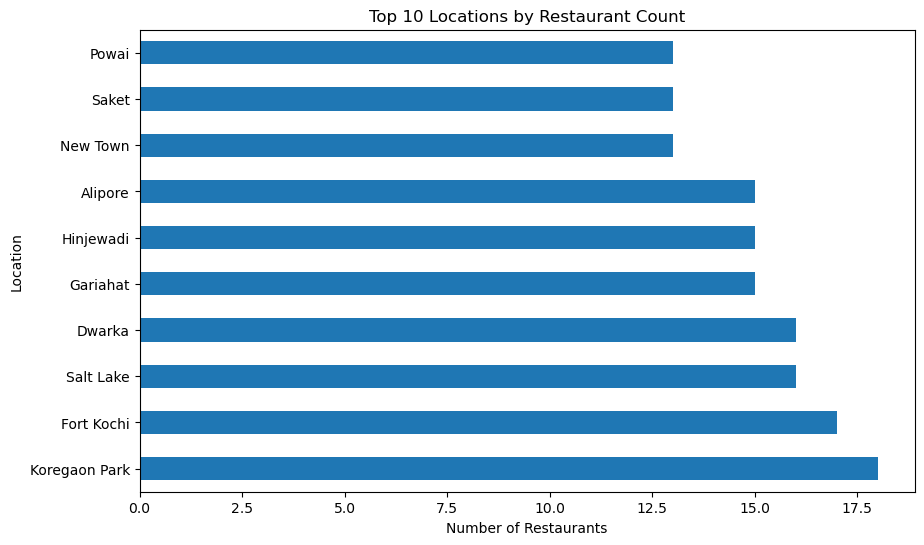

In [86]:
# Count restaurants in each location
location_count = (merged_data.groupby("Location")["Restaurant_ID"].nunique().sort_values(ascending=False)
)

# Get top 10 locations
top_10_locations = location_count.head(10)

# Create bar chart
top_10_locations.plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Locations by Restaurant Count"
)

plt.xlabel("Number of Restaurants")
plt.ylabel("Location")
plt.show()

### Interpretation

The visualization shows that the number of restaurants varies across locations. The top locations have a higher concentration of restaurants, while some locations have fewer restaurants. This indicates that restaurant availability is not evenly distributed across locations.

### 14.2 Restaurant Count by City

This visualization shows the number of unique restaurants available in each city. It highlights the cities with the highest concentration of restaurants in the dataset.

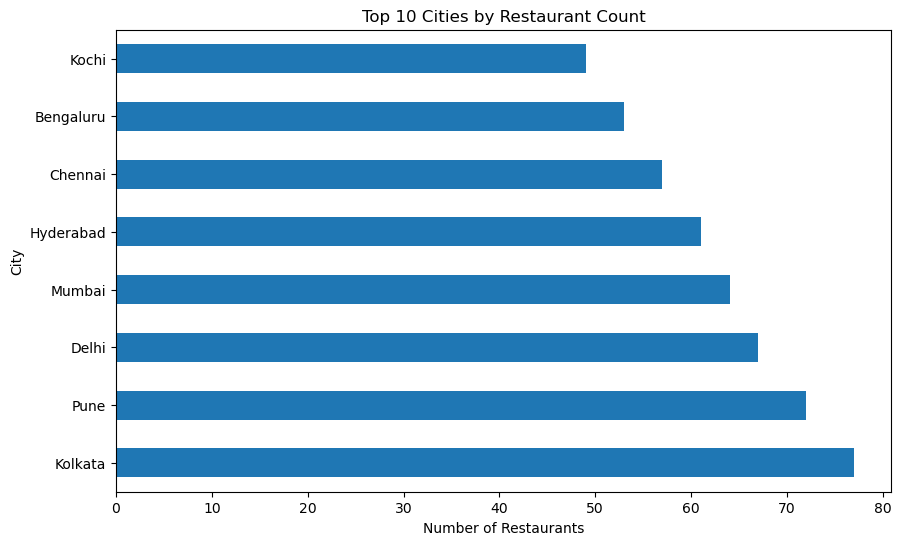

In [95]:
# Count unique restaurants in each city
city_count = (
    merged_data.groupby("City")["Restaurant_ID"]
    .nunique()
    .sort_values(ascending=False)
)

# Get top 10 cities
top_10_cities = city_count.head(10)

# Create bar chart
top_10_cities.plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Cities by Restaurant Count"
)

plt.xlabel("Number of Restaurants")
plt.ylabel("City")
plt.show()

### Interpretation

The visualization shows that the number of restaurants varies across cities. Kolkata has the highest restaurant count among the cities shown, followed by Pune and Delhi. Kochi has the lowest restaurant count among the top 10 cities shown. This indicates that restaurant availability is concentrated more heavily in some cities than others.

## 14.3 Average Rating by Location

This visualization shows the average restaurant rating for each location.

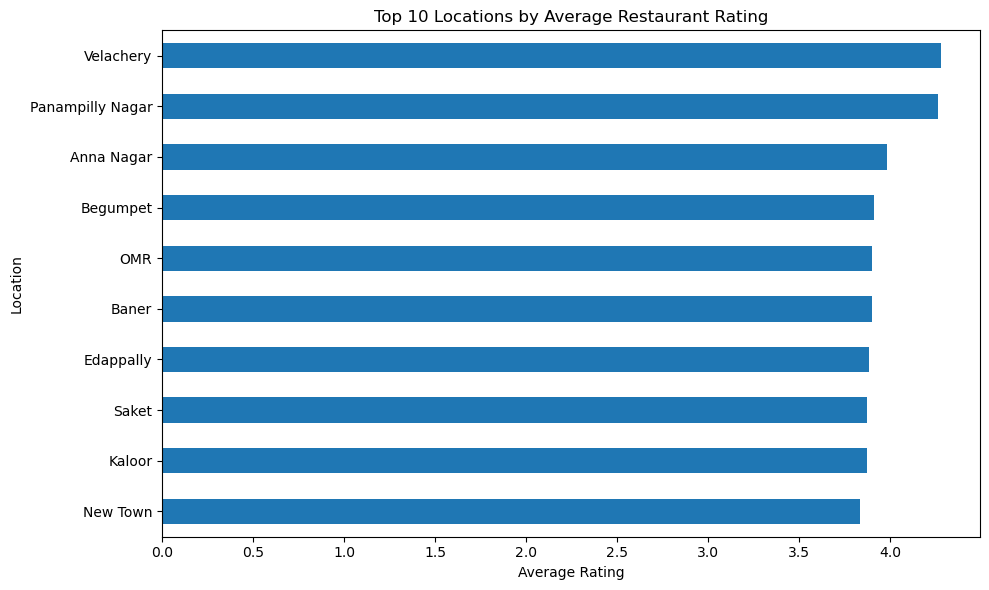

In [92]:
# Calculate average rating for each location
rating_by_location = (
    restaurant_location.groupby("Location")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

# Select top 10 locations
top_10_rating = rating_by_location.head(10).sort_values()

# Create bar chart
top_10_rating.plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Locations by Average Restaurant Rating"
)

plt.xlabel("Average Rating")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

### Interpretation

The visualization shows differences in average restaurant ratings across locations. The top-rated locations have higher average ratings compared with other locations, indicating variation in customer ratings across locations.

## 14.4 Rating Distribution

This visualization shows how restaurant ratings are distributed across the dataset.

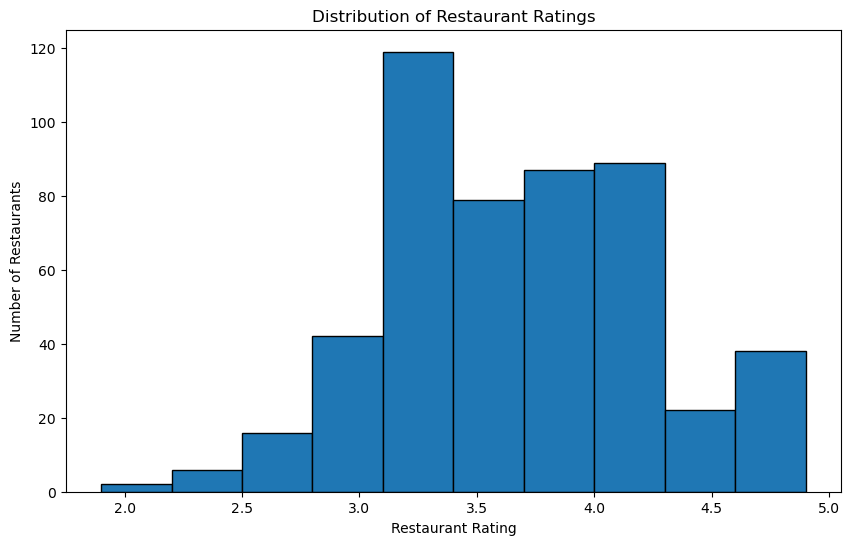

In [58]:
plt.figure(figsize=(10, 6))

plt.hist(
    restaurants_py["Rating"].dropna(),
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Restaurant Rating")
plt.ylabel("Number of Restaurants")

plt.show()

### Interpretation

The rating distribution shows how restaurant ratings are spread across the dataset. Most restaurants are concentrated within a particular rating range, while relatively fewer restaurants have very low or very high ratings.

## 14.5 Rating vs Votes

This visualization examines the relationship between restaurant ratings and the number of votes received by each restaurant.

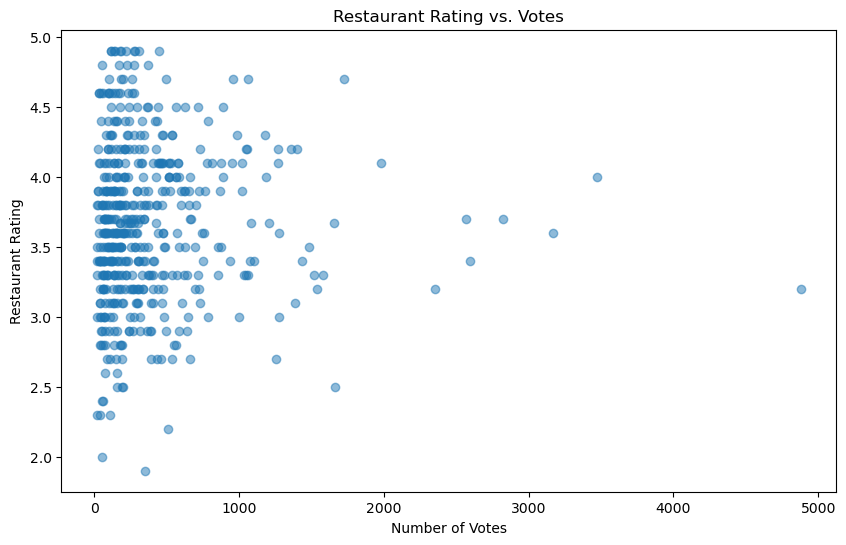

In [59]:
plt.figure(figsize=(10, 6))

plt.scatter(
    restaurants_py["Votes"],
    restaurants_py["Rating"],
    alpha=0.5
)

plt.title("Restaurant Rating vs. Votes")
plt.xlabel("Number of Votes")
plt.ylabel("Restaurant Rating")

plt.show()

### Interpretation – Restaurant Rating vs. Votes

- Most restaurants have a relatively low number of votes, with ratings spread across a wide range.
- Restaurants with higher numbers of votes do not consistently have higher ratings.
- The scatter plot does not show a clear strong linear relationship between the number of votes and restaurant rating.
- A few restaurants have very high vote counts, but their ratings vary, indicating that popularity does not necessarily correspond to a higher rating.

## 14.6 Monthly Completed-Order Revenue

This visualization shows the monthly revenue generated from completed orders. It helps identify changes in revenue over time and highlights months with relatively higher or lower completed-order revenue.

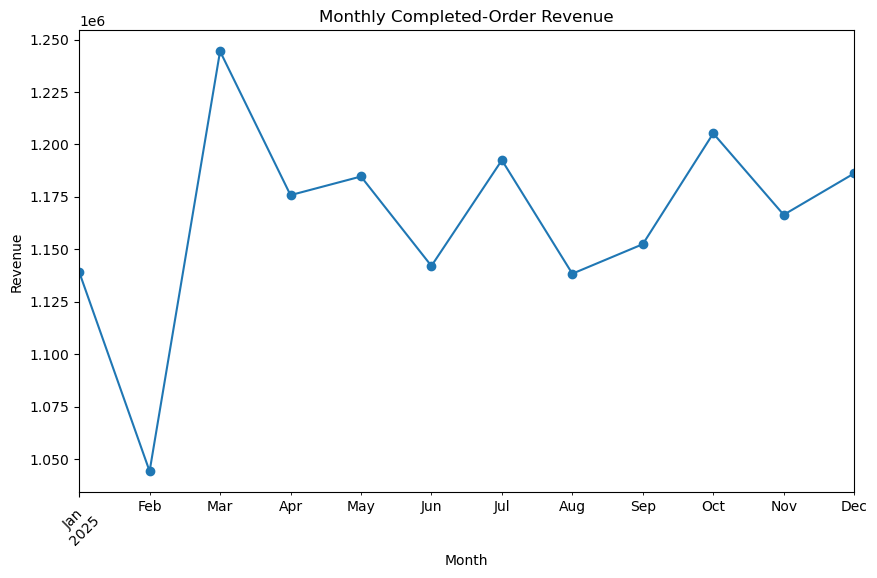

In [60]:
# Convert Order_Date to datetime
orders["Order_Date"] = pd.to_datetime(orders["Order_Date"])

# Keep only completed orders
completed_orders = orders_py[orders_py["Order_Status"] == "Completed"]

# Calculate monthly revenue
monthly_revenue = (
    completed_orders
    .groupby(orders.loc[completed_orders.index, "Order_Date"].dt.to_period("M"))["Order_Value"]
    .sum()
)

# Plot
monthly_revenue.plot(
    figsize=(10, 6),
    marker="o",
    title="Monthly Completed-Order Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

## Interpretation – Monthly Completed-Order Revenue

- The visualization shows the monthly revenue generated from completed orders.
- Revenue varies across the months, indicating changes in completed-order sales over time.
- Some months generate relatively higher revenue, while other months show lower revenue.
- The trend helps identify months with stronger or weaker completed-order performance.

## 14.7 Online Ordering vs. Average Rating

This visualization compares the average restaurant rating between restaurants that offer online ordering and those that do not.

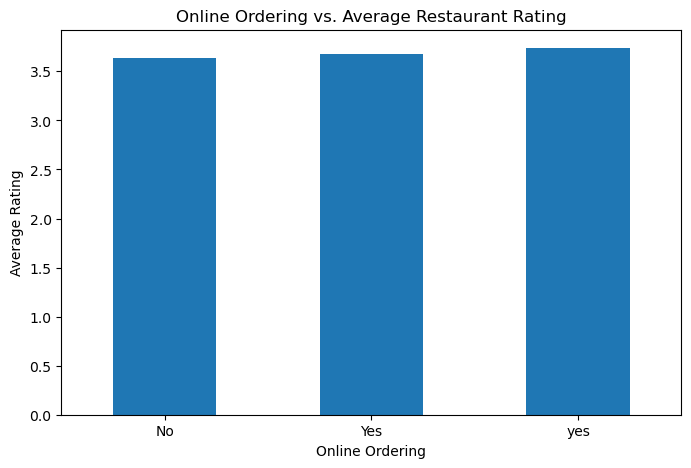

In [61]:
# Calculate average rating by online ordering
online_order_rating = restaurants_py.groupby("Online_Order")["Rating"].mean()

# Create bar chart
online_order_rating.plot(
    kind="bar",
    figsize=(8, 5),
    title="Online Ordering vs. Average Restaurant Rating"
)

plt.xlabel("Online Ordering")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.show()

## Interpretation – Online Ordering vs. Average Rating

- The visualization compares the average ratings of restaurants with and without online ordering.
- Restaurants without online ordering have an average rating of approximately 3.64.
- Restaurants with online ordering have an average rating of approximately 3.68.
- The difference in average rating is small, suggesting that online ordering availability is not strongly associated with restaurant ratings in this dataset.

# 14. Final Insight Summary

The Python analysis provided several useful insights into restaurant performance, customer ratings, ordering behavior, and delivery operations.

### Key Insights

- The dataset was cleaned by handling duplicate records, missing Order_Value values, and invalid Restaurant Rating values. After cleaning, the Orders table contained **19,980 records**.

- Restaurant ratings with the invalid value **-100 were converted to 100**, and missing ratings were imputed using the mean rating, resulting in no missing values in the Rating column.

- The IQR method identified **875 potential outliers in Order_Value**, **99 potential outliers in Delivery_Time**, and **39 potential outliers in Votes**. These values were identified for further investigation rather than automatically removed.

- Location-level analysis showed differences in restaurant distribution and ratings. **L035 had the highest restaurant count with 18 restaurants**, while **L028 had the highest average rating of approximately 4.28**.

- Cuisine-level analysis showed variation in customer ratings. **Cuisine C007 had the highest average rating of approximately 3.87** among the cuisines analyzed.

- Restaurants offering online ordering had an average rating of approximately **3.68**, compared with **3.63** for restaurants without online ordering.

- Restaurants without table booking had an average rating of approximately **3.68**, compared with **3.62** for restaurants offering table booking.

- The average delivery rating was approximately **3.74 for restaurants without online ordering** and **3.72 for restaurants with online ordering**, showing only a small difference.

### Correlation Insights

- **Average Cost vs. Rating:** The correlation was approximately **-0.068**, indicating a very weak negative linear relationship.

- **Votes vs. Rating:** The correlation was approximately **0.014**, indicating almost no linear relationship between the number of votes and restaurant rating.

- **Order Value vs. Delivery Time:** The correlation was approximately **-0.004**, indicating almost no linear relationship between order value and delivery time.

### Overall Conclusion

The analysis shows that restaurant ratings do not appear to have a strong linear relationship with average cost, number of votes, order value, or delivery time. Restaurant performance also varies across locations and cuisines. Online ordering and table booking show only small differences in average restaurant ratings. The outlier analysis highlights unusual order values, delivery times, and vote counts that may require further business investigation rather than automatic removal.

Overall, the Python analysis provides a strong foundation for understanding **restaurant performance, customer ratings, ordering behavior, and operational patterns**, and these findings can be further explored through visualizations and the Power BI dashboard.